### 2. Descriptive Data Analysis

#### 2.1 Numerical Data

In [1]:
# assume small data set of heights of students in a class
import numpy as np

x = np.array([69,64,63,73,74,64,66,70,70,68,67])
xbar = np.mean(x)
print('xbar = {:.4f} for n = {:d} observations'.format(xbar,len(x)))

xbar = 68.0000 for n = 11 observations


In [2]:
x = np.array([69,64,63,73,74,64,66,70,70,68,67,float("nan")])
xbar = np.mean(x); print('regular mean xbar = {:.4f}'.format(xbar))
xbar = np.nanmean(x); print('nanmean() xbar = {:.4f}'.format(xbar))

regular mean xbar = nan
nanmean() xbar = 68.0000


In [3]:
from scipy import stats
x = np.array([69,64,63,73,74,64,66,70,70,68,67,float("nan")])
xbar = stats.trim_mean(x,0.1,nan_policy='omit');
print('trimmed mean xbar = {:.4f}'.format(xbar))

trimmed mean xbar = 67.8889


In [4]:
import pandas as pd

url="https://raw.githubusercontent.com/leonkag/Statistics0/main/HELPrct.csv"
mydata = pd.read_csv(url)
print(mydata[['cesd','pcs','mcs']].head(10)) # first 10 lines for 3 vars
print('\n')

xbar = np.mean(mydata['cesd']) # data column is referenced as ['cesd']
print('mean of cesd = {:.4f}'.format(xbar))

   cesd        pcs        mcs
0    49  58.413689  25.111990
1    30  36.036942  26.670307
2    39  74.806328   6.762923
3    15  61.931679  43.967880
4    39  37.345585  21.675755
5     6  46.475212  55.508991
6    52  24.515039  21.793024
7    32  65.138008   9.160530
8    50  38.270878  22.029678
9    46  22.610598  36.143761


mean of cesd = 32.8477


In [5]:
# mean of several columns at once
print('Mean of the two columns using np.mean:')
print(np.mean(mydata[['cesd','mcs']],axis=0))

print('\nMean of the two colums .mean():')
print(mydata[['cesd','mcs']].mean())

Mean of the two columns using np.mean:
cesd    32.847682
mcs     31.676678
dtype: float64

Mean of the two colums .mean():
cesd    32.847682
mcs     31.676678
dtype: float64


In [6]:
print('Trimmed mean from stats library : ',
      stats.trim_mean(mydata[['cesd','mcs']], 0.05))

Trimmed mean from stats library :  [33.06356968 31.31445885]


<Axes: xlabel='wage', ylabel='Count'>

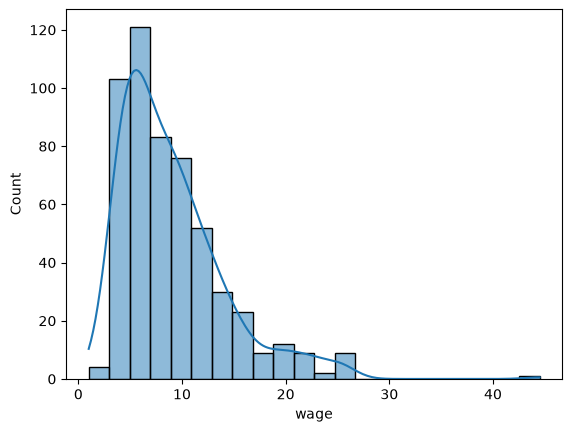

In [7]:
import seaborn as sns

url="https://raw.githubusercontent.com/leonkag/Statistics0/main/CPS85.csv"
mydata = pd.read_csv(url)  # save as mydata file
# print(mydata.head())

sns.histplot(data=mydata, x="wage", binwidth=2, kde=True)
# kde adds kernel density estimate smoothing histogram shape
# of the distribution. The binwidth allows varying the number of bins.

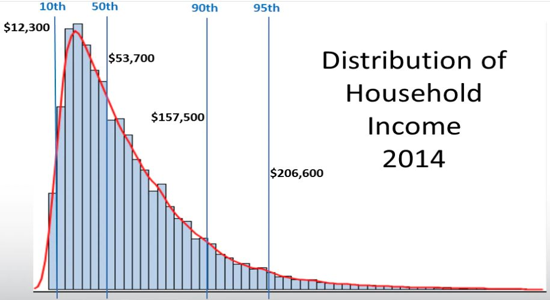

In [8]:
import requests; from io import BytesIO; from PIL import Image

url='https://raw.githubusercontent.com/leonkag/Statistics0/main/Income2014.JPG'

page = requests.get(url); img=Image.open(BytesIO(page.content));
img.resize((550,300))

<Axes: ylabel='Count'>

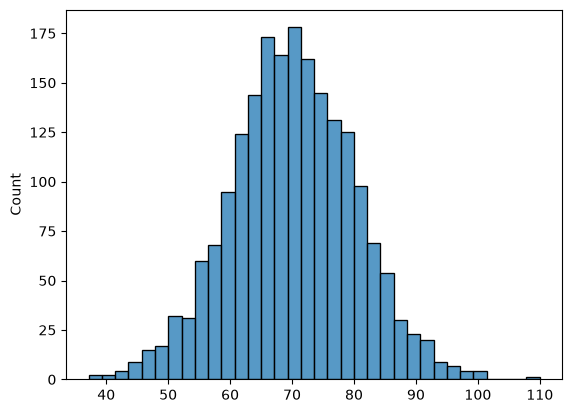

In [9]:
np.random.seed(28)

mean, std_dev = 70, 10
num_scores = 2000

test_scores = np.random.normal(mean, std_dev, num_scores)
sns.histplot(test_scores)

In [11]:
import numpy as np; import pandas as pd
x = np.array([69,64,63,73,74,64,66,70,70,68,67])

# this part of the code is FYI ############################
xbar = np.mean(x)
d = x - xbar;
d2 = d**2  # d^2
stdframe = pd.DataFrame({'x':x,'xbar':np.repeat(xbar,len(x)),'d':d,'d2':d2})
print(stdframe,'\n')
print('sum of deviations =', np.sum(d), '\n')
############################################################################

s = np.std(x,ddof=1);  # sample standard deviation requires ddof=1!!
sig = np.std(x);  # population standard deviation (default)
print('s, sig = ', s, sig)



     x  xbar    d    d2
0   69  68.0  1.0   1.0
1   64  68.0 -4.0  16.0
2   63  68.0 -5.0  25.0
3   73  68.0  5.0  25.0
4   74  68.0  6.0  36.0
5   64  68.0 -4.0  16.0
6   66  68.0 -2.0   4.0
7   70  68.0  2.0   4.0
8   70  68.0  2.0   4.0
9   68  68.0  0.0   0.0
10  67  68.0 -1.0   1.0 

sum of deviations = 0.0 

s, sig =  3.63318042491699 3.4641016151377544


In [12]:
# coefficient of variation
StockA = np.array([1.23,1.50,2.27,0.54,2.40,3.10,5.18])
StockB = np.array([171,169,182,159,164,175,180,173,176,177])

Abar = np.mean(StockA); sa = np.std(StockA,ddof=1); CVa = sa/Abar*100;
print('Company A: ')
print('Mean = {:.3f}, standard deviation = {:.3f}, CV = {:.3f}'.format(Abar,sa,CVa))

Bbar = np.mean(StockB); sb = np.std(StockB,ddof=1); CVb = sb/Bbar*100;
print('Company B: ')
print('Mean = {:.3f}, standard deviation = {:.3f}, CV = {:.3f}'.format(Bbar,sb,CVb))

Company A: 
Mean = 2.317, standard deviation = 1.518, CV = 65.511
Company B: 
Mean = 172.600, standard deviation = 7.106, CV = 4.117


<Axes: xlabel='cesd'>

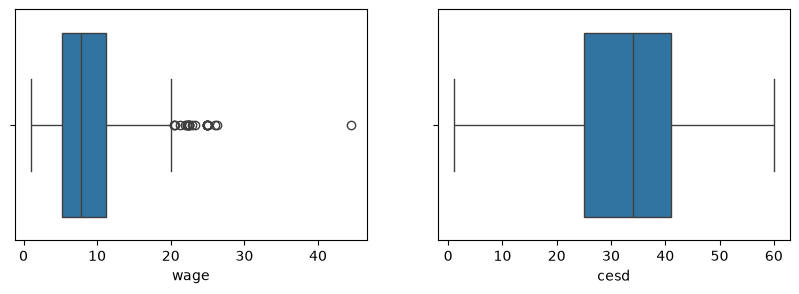

In [13]:
import pandas as pd; import numpy as np;
import seaborn as sns; import matplotlib.pyplot as plt;

url="https://raw.githubusercontent.com/leonkag/Statistics0/main/HELPrct.csv"
HELPrct = pd.read_csv(url)
url="https://raw.githubusercontent.com/leonkag/Statistics0/main/CPS85.csv"
CPS85 = pd.read_csv(url)
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=False)
sns.boxplot(data=CPS85, x="wage", ax=axes[0])
sns.boxplot(data=HELPrct, x="cesd", ax=axes[1])

In [14]:
HELPrct[['cesd','mcs','pcs']].describe()

,cesd,mcs,pcs
count,453.000000,453.000000,453.000000
mean,32.847682,31.676678,48.048542
std,12.514460,12.839337,10.784603
min,1.000000,6.762923,14.074291
25%,25.000000,21.675755,40.384377
50%,34.000000,28.602417,48.876808
75%,41.000000,40.941338,56.953285
max,60.000000,62.175503,74.806328


#### 2.2 Categorical Data

substance
alcohol    177
cocaine    152
heroin     124
Name: count, dtype: int64


<Axes: xlabel='substance'>

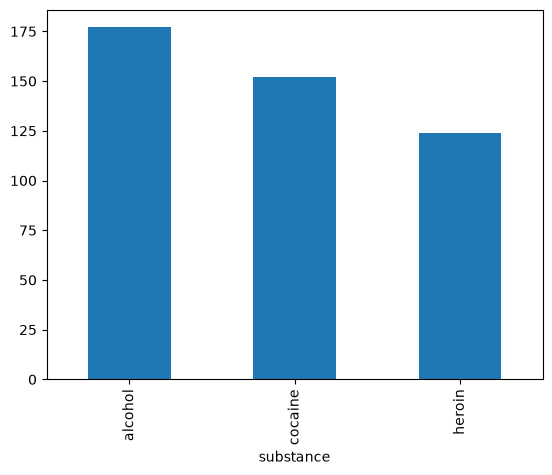

In [15]:
import pandas as pd; import numpy as np; import seaborn as sns
url="https://raw.githubusercontent.com/leonkag/Statistics0/main/HELPrct.csv"
mydata = pd.read_csv(url)  # save as mydata file

mytable = mydata['substance'].value_counts()
print(mytable)
mytable.plot.bar()

substance
alcohol    0.390728
cocaine    0.335541
heroin     0.273731
Name: proportion, dtype: float64


<Axes: xlabel='substance'>

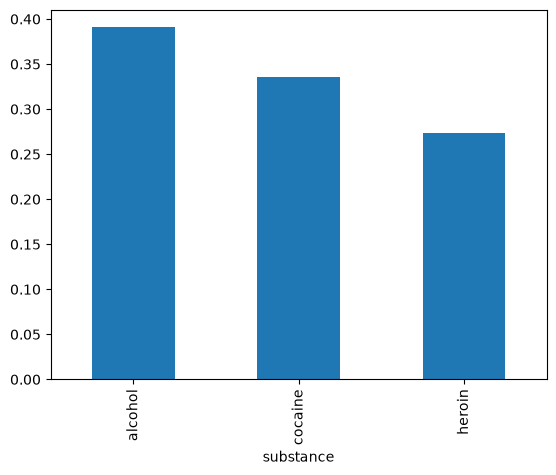

In [16]:
mytable = mydata['substance'].value_counts(normalize=True)
print(mytable)
mytable.plot.bar()

substance  alcohol  cocaine  heroin
homeless                           
homeless       103       59      47
housed          74       93      77 

substance  alcohol  cocaine  heroin  All
homeless                                
homeless       103       59      47  209
housed          74       93      77  244
All            177      152     124  453 



<Axes: xlabel='homeless'>

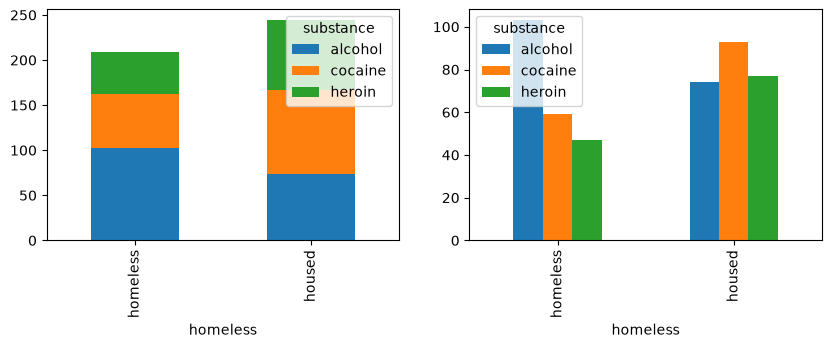

In [19]:
url = "https://raw.githubusercontent.com/leonkag/Statistics0/main/HELPrct.csv"
mydata = pd.read_csv(url)

O = pd.crosstab(mydata.homeless, mydata.substance, margins=False)
Om = pd.crosstab(mydata.homeless, mydata.substance, margins=True)
print(O, '\n')
print(Om, '\n')

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=False)
O.plot.bar(stacked=True,ax=axes[0])
O.plot.bar(stacked=False,ax=axes[1])

In [ ]:
import pandas as pd; import numpy as np;
import seaborn as sns; import matplotlib.pyplot as plt;
url="https://raw.githubusercontent.com/leonkag/Statistics0/main/HELPrct.csv"
mydata = pd.read_csv(url) # save as mydata file

mydata.groupby('sex')['cesd'].describe()

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
female,107.0,36.887850,13.017642,3.0,29.0,38.0,46.5,60.0
male,346.0,31.598266,12.103318,1.0,24.0,32.5,40.0,58.0


<Axes: xlabel='sex', ylabel='cesd'>

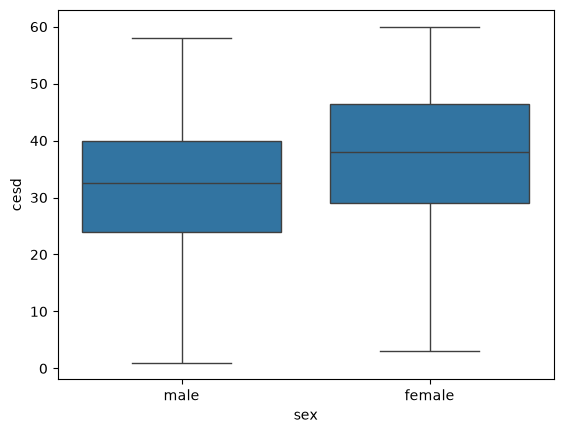

In [21]:
sns.boxplot(data=mydata ,x='sex', y='cesd')

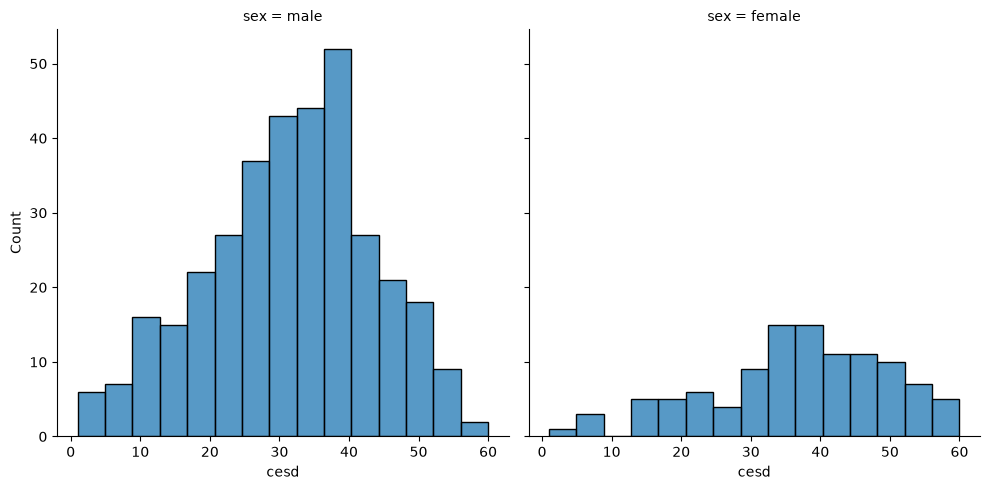

In [23]:
sns.displot(mydata, x='cesd', col='sex')

In [ ]:
sns.kdeplot(data=mydata, x="cesd", hue="sex", cut=0, fill=True, common_norm=False, alpha=0.2)